<a href="https://colab.research.google.com/github/Anaya2306/HackoWeek-SEM-5/blob/main/Week_15_%26_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pickle
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, load_iris
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
np.random.seed(42)

# Train once, save to disk, load later (e.g. inside a Flask/FastAPI app) without retraining.

X, y = load_iris(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

# Saving a whole Pipeline means preprocessing is saved together with the model
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", RandomForestClassifier(n_estimators=100, random_state=42)),
])
pipe.fit(X_tr, y_tr)
print("Original model accuracy:", pipe.score(X_te, y_te))

# --- pickle ---
with open("iris_model.pkl", "wb") as f:
    pickle.dump(pipe, f)
with open("iris_model.pkl", "rb") as f:
    model_pickle = pickle.load(f)
print("pickle-loaded accuracy: ", model_pickle.score(X_te, y_te))

# --- joblib (better for models holding big NumPy arrays) ---
joblib.dump(pipe, "iris_model.joblib")
model_joblib = joblib.load("iris_model.joblib")
print("joblib-loaded accuracy: ", model_joblib.score(X_te, y_te))


# A tiny "deployment" function: this is what an API endpoint would call
def predict_species(sepal_len, sepal_wid, petal_len, petal_wid):
    model = joblib.load("iris_model.joblib")
    names = ["setosa", "versicolor", "virginica"]
    return names[model.predict([[sepal_len, sepal_wid, petal_len, petal_wid]])[0]]


print("Prediction for a new flower:", predict_species(5.1, 3.5, 1.4, 0.2))

Original model accuracy: 1.0
pickle-loaded accuracy:  1.0
joblib-loaded accuracy:  1.0
Prediction for a new flower: setosa


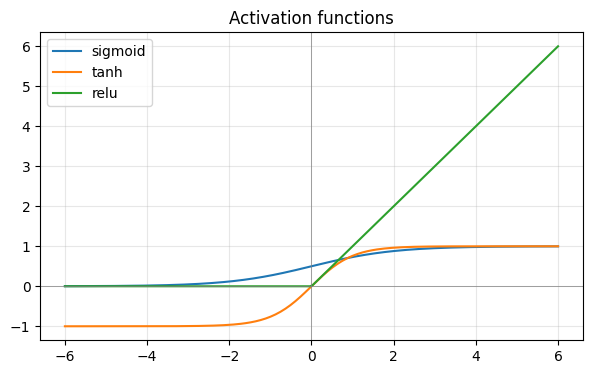

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def sigmoid_grad(a):          # takes the OUTPUT a = sigmoid(z)
    return a * (1 - a)

def tanh(z):
    return np.tanh(z)

def tanh_grad(a):             # takes the OUTPUT a = tanh(z)
    return 1 - a ** 2

def relu(z):
    return np.maximum(0, z)

def relu_grad(a):             # takes the OUTPUT a = relu(z)
    return (a > 0).astype(float)

def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)   # numerical stability
    e = np.exp(z)
    return e / np.sum(e, axis=1, keepdims=True)

ACTIVATIONS = {
    "sigmoid": (sigmoid, sigmoid_grad),
    "tanh": (tanh, tanh_grad),
    "relu": (relu, relu_grad),
    "linear": (lambda z: z, lambda a: np.ones_like(a)),
}

# Plot them
z = np.linspace(-6, 6, 200)
plt.figure(figsize=(7, 4))
for name in ["sigmoid", "tanh", "relu"]:
    plt.plot(z, ACTIVATIONS[name][0](z), label=name)
plt.axhline(0, color="gray", lw=0.5); plt.axvline(0, color="gray", lw=0.5)
plt.title("Activation functions"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [4]:
class Perceptron:
    def __init__(self, n_features, lr=0.1, epochs=20):
        self.w = np.zeros(n_features)
        self.b = 0.0
        self.lr = lr
        self.epochs = epochs

    def predict(self, X):
        return (X @ self.w + self.b >= 0).astype(int)   # step function

    def fit(self, X, y):
        for epoch in range(self.epochs):
            errors = 0
            for xi, yi in zip(X, y):
                pred = int(xi @ self.w + self.b >= 0)
                update = self.lr * (yi - pred)
                self.w += update * xi
                self.b += update
                errors += int(update != 0)
            if errors == 0:
                print(f"  converged at epoch {epoch + 1}")
                break
        return self


X_gate = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
for gate, y_gate in {"AND": [0, 0, 0, 1], "OR": [0, 1, 1, 1], "XOR": [0, 1, 1, 0]}.items():
    print(f"Perceptron on {gate}:")
    p = Perceptron(2).fit(X_gate, np.array(y_gate))
    print("  predictions:", p.predict(X_gate), "| target:", y_gate)

Perceptron on AND:
  converged at epoch 4
  predictions: [0 0 0 1] | target: [0, 0, 0, 1]
Perceptron on OR:
  converged at epoch 4
  predictions: [0 1 1 1] | target: [0, 1, 1, 1]
Perceptron on XOR:
  predictions: [1 1 0 0] | target: [0, 1, 1, 0]


In [5]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def mse_grad(y_true, y_pred):
    return 2 * (y_pred - y_true) / y_true.shape[0]

def binary_cross_entropy(y_true, y_pred, eps=1e-12):
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

def bce_grad(y_true, y_pred, eps=1e-12):
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return (-(y_true / y_pred) + (1 - y_true) / (1 - y_pred)) / y_true.shape[0]

LOSSES = {
    "mse": (mse, mse_grad),
    "bce": (binary_cross_entropy, bce_grad),
}



In [6]:
class SGD:
    """w <- w - lr * grad   (optional momentum)"""
    def __init__(self, lr=0.1, momentum=0.0):
        self.lr, self.momentum = lr, momentum
        self.v = {}

    def update(self, key, param, grad):
        v = self.v.get(key, np.zeros_like(param))
        v = self.momentum * v - self.lr * grad
        self.v[key] = v
        return param + v


class Adam:
    """Momentum (m) + per-parameter adaptive learning rate (v), with bias correction."""
    def __init__(self, lr=0.01, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps = lr, beta1, beta2, eps
        self.m, self.v, self.t = {}, {}, {}

    def update(self, key, param, grad):
        t = self.t.get(key, 0) + 1
        m = self.b1 * self.m.get(key, np.zeros_like(param)) + (1 - self.b1) * grad
        v = self.b2 * self.v.get(key, np.zeros_like(param)) + (1 - self.b2) * grad ** 2
        self.m[key], self.v[key], self.t[key] = m, v, t
        m_hat = m / (1 - self.b1 ** t)
        v_hat = v / (1 - self.b2 ** t)
        return param - self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

In [9]:
class NeuralNetwork:
    def __init__(self, layer_sizes, activations, loss="bce", optimizer=None, seed=42):
        """
        layer_sizes : e.g. [2, 8, 8, 1]
        activations : one per layer transition, e.g. ["relu", "relu", "sigmoid"]
        """
        rng = np.random.default_rng(seed)
        self.activations = activations
        self.loss_fn, self.loss_grad = LOSSES[loss]
        self.optimizer = optimizer or SGD(lr=0.1)
        self.W, self.b = [], []
        for n_in, n_out, act in zip(layer_sizes[:-1], layer_sizes[1:], activations):
            # He init for ReLU, Xavier otherwise
            scale = np.sqrt(2 / n_in) if act == "relu" else np.sqrt(1 / n_in)
            self.W.append(rng.normal(0, scale, (n_in, n_out)))
            self.b.append(np.zeros((1, n_out)))
        self.history = []

    # ---------- forward propagation ----------
    def forward(self, X):
        self.a = [X]                          # cache activations for backprop
        for W, b, act in zip(self.W, self.b, self.activations):
            z = self.a[-1] @ W + b
            self.a.append(ACTIVATIONS[act][0](z))
        return self.a[-1]

    # ---------- backward propagation ----------
    def backward(self, y_true):
        grads_W, grads_b = [None] * len(self.W), [None] * len(self.W)
        y_pred = self.a[-1]

        # dL/da at the output, then multiply by da/dz  (chain rule)
        delta = self.loss_grad(y_true, y_pred) * ACTIVATIONS[self.activations[-1]][1](y_pred)

        for i in reversed(range(len(self.W))):
            grads_W[i] = self.a[i].T @ delta               # dL/dW
            grads_b[i] = np.sum(delta, axis=0, keepdims=True)  # dL/db
            if i > 0:
                # push the error back through W, then through the previous activation
                delta = (delta @ self.W[i].T) * ACTIVATIONS[self.activations[i - 1]][1](self.a[i])
        return grads_W, grads_b

    def step(self, grads_W, grads_b):
        for i in range(len(self.W)):
            self.W[i] = self.optimizer.update(f"W{i}", self.W[i], grads_W[i])
            self.b[i] = self.optimizer.update(f"b{i}", self.b[i], grads_b[i])

    def fit(self, X, y, epochs=1000, batch_size=None, verbose=200):
        n = X.shape[0]
        batch_size = batch_size or n
        for epoch in range(1, epochs + 1):
            idx = np.random.permutation(n)
            for start in range(0, n, batch_size):
                batch = idx[start:start + batch_size]
                self.forward(X[batch])
                gW, gb = self.backward(y[batch])
                self.step(gW, gb)
            loss = self.loss_fn(y, self.forward(X))
            self.history.append(loss)
            if verbose and epoch % verbose == 0:
                acc = np.mean((self.forward(X) > 0.5) == y)
                print(f"  epoch {epoch:4d} | loss {loss:.4f} | acc {acc:.3f}")
        return self

    def predict(self, X, threshold=0.5):
        return (self.forward(X) > threshold).astype(int)

    # ---------- save / load (ties back to Part 1) ----------
    def save(self, path):
        joblib.dump({"W": self.W, "b": self.b, "activations": self.activations}, path)

    @staticmethod
    def load(path, loss="bce"):
        d = joblib.load(path)
        sizes = [d["W"][0].shape[0]] + [w.shape[1] for w in d["W"]]
        net = NeuralNetwork(sizes, d["activations"], loss=loss)
        net.W, net.b = d["W"], d["b"]
        return net



In [10]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([[0], [1], [1], [0]], dtype=float)

net_xor = NeuralNetwork([2, 4, 1], ["tanh", "sigmoid"], loss="bce", optimizer=Adam(lr=0.05))
net_xor.fit(X_xor, y_xor, epochs=1000, verbose=250)
print("XOR predictions:", net_xor.predict(X_xor).ravel(), "| target:", y_xor.ravel().astype(int))

  epoch  250 | loss 0.0051 | acc 1.000
  epoch  500 | loss 0.0018 | acc 1.000
  epoch  750 | loss 0.0009 | acc 1.000
  epoch 1000 | loss 0.0006 | acc 1.000
XOR predictions: [0 1 1 0] | target: [0 1 1 0]


In [11]:
def gradient_check(net, X, y, eps=1e-5):
    net.forward(X)
    gW, _ = net.backward(y)
    max_diff = 0
    for i in range(len(net.W)):
        for _ in range(5):                                   # check 5 random weights per layer
            r, c = np.random.randint(net.W[i].shape[0]), np.random.randint(net.W[i].shape[1])
            orig = net.W[i][r, c]
            net.W[i][r, c] = orig + eps; l1 = net.loss_fn(y, net.forward(X))
            net.W[i][r, c] = orig - eps; l2 = net.loss_fn(y, net.forward(X))
            net.W[i][r, c] = orig
            numeric = (l1 - l2) / (2 * eps)
            max_diff = max(max_diff, abs(numeric - gW[i][r, c]))
    return max_diff

check_net = NeuralNetwork([2, 5, 1], ["tanh", "sigmoid"], loss="bce")
print("Max gradient difference (should be ~1e-8 or smaller):", gradient_check(check_net, X_xor, y_xor))

Max gradient difference (should be ~1e-8 or smaller): 7.478418925788155e-12


Training with SGD:
  epoch  100 | loss 0.1115 | acc 0.960
  epoch  200 | loss 0.0920 | acc 0.967
  epoch  300 | loss 0.0870 | acc 0.967
  epoch  400 | loss 0.0987 | acc 0.962
Training with Adam:
  epoch  100 | loss 0.0888 | acc 0.967
  epoch  200 | loss 0.0915 | acc 0.964
  epoch  300 | loss 0.0796 | acc 0.973
  epoch  400 | loss 0.0762 | acc 0.973
SGD test accuracy: 0.960
Adam test accuracy: 0.953


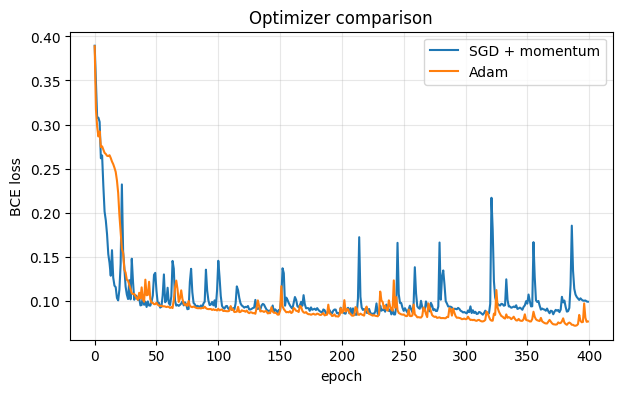

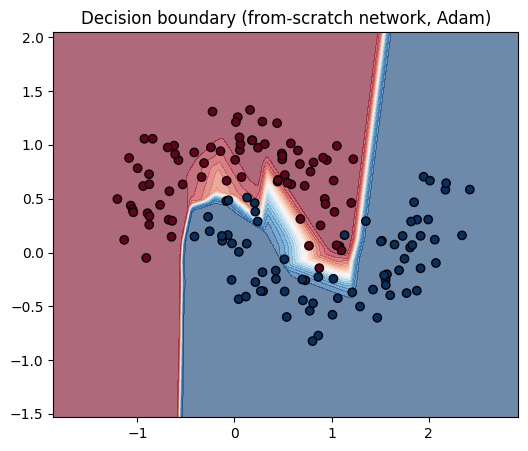

Restored model test accuracy: 0.9533333333333334


In [12]:
Xm, ym = make_moons(n_samples=600, noise=0.2, random_state=42)
ym = ym.reshape(-1, 1).astype(float)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.25, random_state=42)

print("Training with SGD:")
net_sgd = NeuralNetwork([2, 16, 16, 1], ["relu", "relu", "sigmoid"],
                        optimizer=SGD(lr=0.1, momentum=0.9))
net_sgd.fit(Xm_tr, ym_tr, epochs=400, batch_size=32, verbose=100)

print("Training with Adam:")
net_adam = NeuralNetwork([2, 16, 16, 1], ["relu", "relu", "sigmoid"],
                         optimizer=Adam(lr=0.01))
net_adam.fit(Xm_tr, ym_tr, epochs=400, batch_size=32, verbose=100)

for name, net in [("SGD", net_sgd), ("Adam", net_adam)]:
    print(f"{name} test accuracy: {np.mean(net.predict(Xm_te) == ym_te):.3f}")

# Loss curves
plt.figure(figsize=(7, 4))
plt.plot(net_sgd.history, label="SGD + momentum")
plt.plot(net_adam.history, label="Adam")
plt.xlabel("epoch"); plt.ylabel("BCE loss"); plt.title("Optimizer comparison")
plt.legend(); plt.grid(alpha=0.3); plt.show()

# Decision boundary
xx, yy = np.meshgrid(np.linspace(Xm[:, 0].min() - .5, Xm[:, 0].max() + .5, 300),
                     np.linspace(Xm[:, 1].min() - .5, Xm[:, 1].max() + .5, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = net_adam.forward(grid).reshape(xx.shape)
plt.figure(figsize=(6, 5))
plt.contourf(xx, yy, zz, levels=20, cmap="RdBu", alpha=0.6)
plt.scatter(Xm_te[:, 0], Xm_te[:, 1], c=ym_te.ravel(), cmap="RdBu", edgecolor="k")
plt.title("Decision boundary (from-scratch network, Adam)")
plt.show()


net_adam.save("moons_net.joblib")
restored = NeuralNetwork.load("moons_net.joblib")

print("Restored model test accuracy:", np.mean(restored.predict(Xm_te) == ym_te))